# Exploratory data analysis (EDA)
To identify our missing values we will begin with an EDA of our dataset. We will be using some useful python packages, pandas and numpy, to store our data and make some simple calculations as well as some popular visualization tools to see what the distribution of our data looks like. Let's begin and dive into some code. First, we will do some imports:

In [1]:
# import packages we need for exploratory data analysis (EDA)
import pandas as pd # to store tabular data
import numpy as np # to do some math
import matplotlib.pyplot as plt # a popular data visualization tool
import seaborn as sns  # another popular data visualization tool
%matplotlib inline 
plt.style.use('fivethirtyeight') # a popular data visualization theme

In [4]:
#We will import our tabular data through a CSV, as follows:

# load in our dataset using pandas
pima = pd.read_csv('diabetes.csv')

pima.head()

,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


In [5]:
pima_column_names = ['times_pregnant', 'plasma_glucose_concentration', 'diastolic_blood_pressure', 'triceps_thickness', 'serum_insulin', 'bmi', 'pedigree_function', 'age', 'onset_diabetes']

pima = pd.read_csv('diabetes.csv', names=pima_column_names)

pima.head()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Much better, now we can use the column names to do some basic stats, selecting, and visualizations. Let's first get our null accuracy as follows:

In [6]:
pima['onset_diabetes'].value_counts(normalize=True) 
# get null accuracy, 65% did not develop diabetes


0    0.651042
1    0.348958
Name: onset_diabetes, dtype: float64

If our eventual goal is to exploit patterns in our data in order to predict the onset of diabetes, let us try to visualize some of the differences between those that developed diabetes and those that did not. Our hope is that the histogram will reveal some sort of pattern, or obvious difference in values between the classes of prediction:

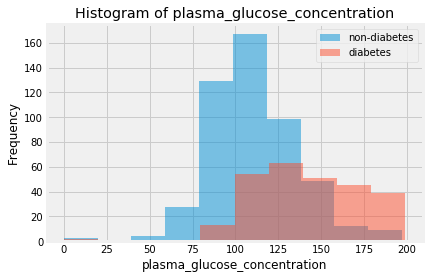

In [7]:
# get a histogram of the plasma_glucose_concentration column for
# both classes

col = 'plasma_glucose_concentration'
plt.hist(pima[pima['onset_diabetes']==0][col], 10, alpha=0.5, label='non-diabetes')
plt.hist(pima[pima['onset_diabetes']==1][col], 10, alpha=0.5, label='diabetes')
plt.legend(loc='upper right')
plt.xlabel(col)
plt.ylabel('Frequency')
plt.title('Histogram of {}'.format(col))
plt.show()

It seems that this histogram is showing us a pretty big difference between plasma_glucose_concentration between the two prediction classes. Let's show the same histogram style for multiple columns as follows:

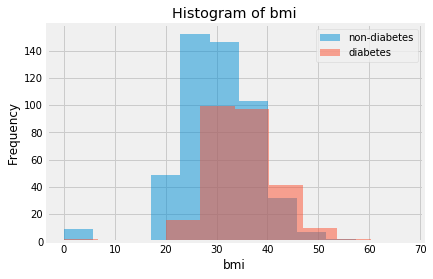

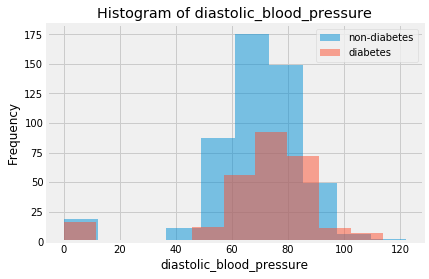

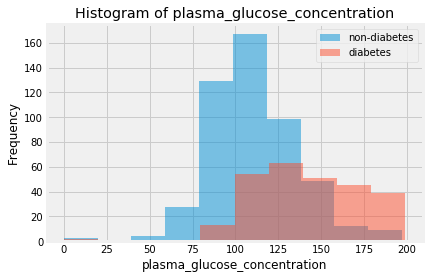

In [8]:
for col in ['bmi', 'diastolic_blood_pressure', 'plasma_glucose_concentration']:
    plt.hist(pima[pima['onset_diabetes']==0][col], 10, alpha=0.5, label='non-diabetes')
    plt.hist(pima[pima['onset_diabetes']==1][col], 10, alpha=0.5, label='diabetes')
    plt.legend(loc='upper right')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.title('Histogram of {}'.format(col))
    plt.show()

The output of the preceding code will give us the following three histograms. The first one is show us the distributions of bmi for the two class variables (non-diabetes and diabetes):

We can definitely see some major differences simply by looking at just a few histograms. For example, there seems to be a large jump in plasma_glucose_concentration for those who will eventually develop diabetes. To solidify this, perhaps we can visualize a linear correlation matrix in an attempt to quantify the relationship between these variables. We will use the visualization tool, seaborn, which we imported at the beginning of this chapter for our correlation matrix as follows:

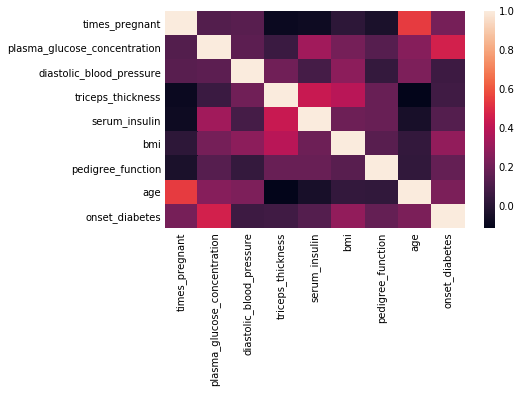

In [10]:
# look at the heatmap of the correlation matrix of our dataset
sns.heatmap(pima.corr())
# plasma_glucose_concentration definitely seems to be an interesting feature here

#Following is the correlation matrix of our dataset. This is showing us the correlation amongst 
#the different columns in our Pima dataset. The output is as follows:

This correlation matrix is showing a strong correlation between plasma_glucose_concentration and onset_diabetes. Let's take a further look at the numerical correlations for the onset_diabetes column, with the following code:

In [11]:
pima.corr()['onset_diabetes'] # numerical correlation matrix
# plasma_glucose_concentration definitely seems to be an interesting feature here

times_pregnant                  0.221898
plasma_glucose_concentration    0.466581
diastolic_blood_pressure        0.065068
triceps_thickness               0.074752
serum_insulin                   0.130548
bmi                             0.292695
pedigree_function               0.173844
age                             0.238356
onset_diabetes                  1.000000
Name: onset_diabetes, dtype: float64

We will explore the powers of correlation in a later Chapter 4, Feature Construction, but for now we are using exploratory data analysis (EDA) to hint at the fact that the plasma_glucose_concentration column will be an important factor in our prediction of the onset of diabetes.

Moving on to more important matters at hand, let's see if we are missing any values in our dataset by invoking the built-in isnull() method of the pandas DataFrame:

In [12]:
pima.isnull().sum()

times_pregnant                  0
plasma_glucose_concentration    0
diastolic_blood_pressure        0
triceps_thickness               0
serum_insulin                   0
bmi                             0
pedigree_function               0
age                             0
onset_diabetes                  0
dtype: int64

Great! We don't have any missing values. Let's go on to do some more EDA, first using the shape method to see the number of rows and columns we are working with:

In [13]:
pima.shape

(768, 9)

Confirming we have 9 columns (including our response variable) and 768 data observations (rows). Now, let's take a peak at the percentage of patients who developed diabetes, using the following code: 

In [14]:
pima['onset_diabetes'].value_counts(normalize=True) 
# get null accuracy, 65% did not develop diabetes

0    0.651042
1    0.348958
Name: onset_diabetes, dtype: float64

This shows us that 65% of the patients did not develop diabetes, while about 35% did. We can use a nifty built-in method of a pandas DataFrame called describe to look at some basic descriptive statistics:

In [15]:
pima.describe()  # get some basic descriptive statistics

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


This shows us quite quickly some basic stats such as mean, standard deviation, and some different percentile measurements of our data. But, notice that the minimum value of the BMI column is 0. That is medically impossible; there must be a reason for this to happen. Perhaps the number zero has been encoded as a missing value instead of the None value or a missing cell. Upon closer inspection, we see that the value 0 appears as a minimum value for the following columns:

1. times_pregnant
2. plasma_glucose_concentration
3.diastolic_blood_pressure
4. triceps_thickness
5. serum_insulin
6. bmi
7. onset_diabetes

Because zero is a class for onset_diabetes and 0 is actually a viable number for times_pregnant, we may conclude that the number 0 is encoding missing values for:

1.plasma_glucose_concentration
2. diastolic_blood_pressure
3. triceps_thickness
4. serum_insulin
5. bmi

So, we actually do having missing values! It was obviously not luck that we happened upon the zeros as missing values, we knew it beforehand. As a data scientist, you must be ever vigilant and make sure that you know as much about the dataset as possible in order to find missing values encoded as other symbols. Be sure to read any and all documentation that comes with open datasets in case they mention any missing values.

If no documentation is available, some common values used instead of missing values are:

1. 0 (for numerical values)
2. unknown or Unknown (for categorical variables)
3. ? (for categorical variables)
So, we have five columns in which missing values exist, so now we get to talk about how to deal with them, in depth.

# Dealing with missing values in a dataset

When working with data, one of the most common issues a data scientist will run into is the problem of missing data. Most commonly, this refers to empty cells (row/column intersections) where the data just was not acquired for whatever reason. This can become a problem for many reasons; notably, when applying learning algorithms to data with missing values, most (not all) algorithms are not able to cope with missing values. 

For this reason, data scientists and machine learning engineers have many tricks and tips on how to deal with this problem. Although there are many variations of methodologies, the two major ways in which we can deal with missing data are:

1. Remove rows with missing values in them
2. Impute (fill in) missing values
3. Each method will clean our dataset to a point where a learning algorithm can handle it, but each method will have its pros and cons.

In [16]:
# Our number of missing values is (incorrectly) 0
pima['serum_insulin'].isnull().sum()



pima['serum_insulin'] = pima['serum_insulin'].map(lambda x:x if x != 0 else None)
# manually replace all 0's with a None value

pima['serum_insulin'].isnull().sum()
# check the number of missing values again



374

In [17]:
# A little faster now for all columns

columns = ['serum_insulin', 'bmi', 'plasma_glucose_concentration', 'diastolic_blood_pressure', 'triceps_thickness']

for col in columns:
    pima[col].replace([0], [None], inplace=True)

So, now if we try to count the number of missing values using the isnull method, we should start to see missing values being counted as follows:

In [18]:
pima.isnull().sum()  # this makes more sense now!

times_pregnant                    0
plasma_glucose_concentration      5
diastolic_blood_pressure         35
triceps_thickness               227
serum_insulin                   374
bmi                              11
pedigree_function                 0
age                               0
onset_diabetes                    0
dtype: int64

In [19]:
#Now that we have missing values properly injected into our dataset 
#instead of the 0 placeholders that the dataset originally came with, our exploratory data analysis will be more accurate:

pima.describe()  # grab some descriptive statistics

,times_pregnant,serum_insulin,pedigree_function,age,onset_diabetes
count,768.000000,394.000000,768.000000,768.000000,768.000000
mean,3.845052,155.548223,0.471876,33.240885,0.348958
std,3.369578,118.775855,0.331329,11.760232,0.476951
min,0.000000,14.000000,0.078000,21.000000,0.000000
25%,1.000000,76.250000,0.243750,24.000000,0.000000
50%,3.000000,125.000000,0.372500,29.000000,0.000000
75%,6.000000,190.000000,0.626250,41.000000,1.000000
max,17.000000,846.000000,2.420000,81.000000,1.000000


In [20]:
pima['plasma_glucose_concentration'].mean(), pima['plasma_glucose_concentration'].std()

(121.6867627785059, 30.53564107280403)

Let us move on to our two ways of dealing with missing data.

# Removing harmful rows of data
Probably the most common and easiest of our two options for dealing with missing data is to simply remove the observations that have any missing values. By doing so, we will be left with only the complete data points with all data filled in. We can obtain a new DataFrame by invoking the dropna method in pandas, as shown in the following code:

In [21]:
# drop the rows with missing values
pima_dropped = pima.dropna()

Now, of course, the obvious problem here is that we lost a few rows. To check how many exactly, use the following code:

In [25]:
num_rows_lost = round(100*(pima.shape[0] - pima_dropped.shape[0])/float(pima.shape[0]))

num_rows_lost

49

Wow! We lost about 51% of the rows from the original dataset, and if we think about this from a machine learning perspective, even though now we have clean data with everything filled in, we aren't really learning as much as we possibly could be by ignoring over half of the data's observations. That's like a doctor trying to understand how heart attacks happen, ignoring over half of their patients coming in for check-ups.

Let's perform some more EDA on the dataset and compare the statistics about the data from before and after dropping the missing-values rows:

In [26]:
# some EDA of the dataset before it was dropped and after

# split of trues and falses before rows dropped
pima['onset_diabetes'].value_counts(normalize=True)

0    0.651042
1    0.348958
Name: onset_diabetes, dtype: float64

Now, let's look at the same split after we dropped the rows, using the following code:

In [27]:
pima_dropped['onset_diabetes'].value_counts(normalize=True)  

0    0.668367
1    0.331633
Name: onset_diabetes, dtype: float64

It seems that the binary response stayed relatively the same during the drastic transformation of our dataset. Let's take a look at the shape of our data by comparing the average values of columns before and after the transformation, using the pima.mean function, as follows:

In [28]:
# the mean values of each column (excluding missing values)
pima.mean()

times_pregnant                    3.845052
plasma_glucose_concentration    121.686763
diastolic_blood_pressure         72.405184
triceps_thickness                29.153420
serum_insulin                   155.548223
bmi                              32.457464
pedigree_function                 0.471876
age                              33.240885
onset_diabetes                    0.348958
dtype: float64

And now for the same averages after dropping the rows, using the pima_dropped.mean() function, as follows:

In [29]:
# the mean values of each column (with missing values rows dropped)
pima_dropped.mean()

times_pregnant                    3.301020
plasma_glucose_concentration    122.627551
diastolic_blood_pressure         70.663265
triceps_thickness                29.145408
serum_insulin                   156.056122
bmi                              33.086224
pedigree_function                 0.523046
age                              30.864796
onset_diabetes                    0.331633
dtype: float64

To get a better look at how these numbers changed, let's create a new chart that visualizes the percentages changed on average for each column. First, let's create a table of the percent changes in the average values of each column, as shown in the following code:

In [30]:
# % change in means
(pima_dropped.mean() - pima.mean()) / pima.mean()

times_pregnant                 -0.141489
plasma_glucose_concentration    0.007731
diastolic_blood_pressure       -0.024058
triceps_thickness              -0.000275
serum_insulin                   0.003265
bmi                             0.019372
pedigree_function               0.108439
age                            -0.071481
onset_diabetes                 -0.049650
dtype: float64

And now let's visualize these changes as a bar chart, using the following code:

Text(0, 0.5, '% change')

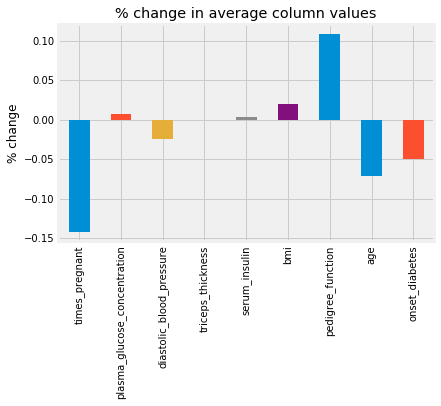

In [31]:
# % change in means as a bar chart
ax = ((pima_dropped.mean() - pima.mean()) / pima.mean()).plot(kind='bar', title='% change in average column values')
ax.set_ylabel('% change')

We can see that the number of times_pregnant variable average fell 14% after dropping missing values, which is a big change! The pedigree_function also rose 11%, another big leap. We can see how dropping rows (observations) severely affects the shape of the data and we should try to retain as much data as possible. Before moving on to the next method of dealing with missing values, let's introduce some actual machine learning into the mix.

The following code block (which we will go over line by line in a moment) will become a very familiar code block in this book. It describes and achieves a single fitting of a machine learning model over a variety of parameters in the hope of obtaining the best possible model, given the features at hand:

In [34]:
# now lets do some machine learning

# note we are using the dataset with the dropped rows

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

X_dropped = pima_dropped.drop('onset_diabetes', axis=1)
# create our feature matrix by removing the response variable
#print "learning from {} rows".format(X_dropped.shape[0])
y_dropped = pima_dropped['onset_diabetes']

In [37]:
# our grid search variables and instances

# KNN parameters to try
knn_params = {'n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

knn = KNeighborsClassifier()  # instantiate a KNN model

grid = GridSearchCV(knn, knn_params)
grid.fit(X_dropped, y_dropped)

print (grid.best_score_, grid.best_params_)
# but we are learning from way fewer rows..

0.7448979591836735 {'n_neighbors': 7}


OK, let's go through this line by line. First, we have two new import statements:

In [38]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

We will be utilizing scikit-learn's K-Nearest Neighbors (KNN) classification model, as well as a grid search module that will automatically find the best combo of parameters (using brute force) for the KNN model that best fits our data with respect to cross-validated accuracy. Next, let's take our dropped dataset (with the missing-valued rows removed) and create an X and a y variable for our predictive model. Let's start with our X (our feature matrix):

In [40]:
X_dropped = pima_dropped.drop('onset_diabetes', axis=1) 
# create our feature matrix by removing the response variable
print ("learning from {} rows".format(X_dropped.shape[0]))

learning from 392 rows


Ouch, it's already obvious that there's a major problem with this approach. Our machine learning algorithm is going to be fitting and learning from far fewer data observations than which we started with. Let's now create our y (response series):

In [41]:
y_dropped = pima_dropped['onset_diabetes']

Now that we have our X and our y variable, we can introduce the variables and instances we need to successfully run a grid search. We will set the number of params to try at seven to keep things simple in this chapter. For every data cleaning and feature engineering method we try (dropping rows, filling in data), we will try to fit the best KNN as having somewhere between one and seven neighbors complexity. We can set this model up as follows:

In [42]:
# our grid search variables and instances

# KNN parameters to try

knn_params = {'n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

Next, we will instantiate a grid search module, as shown in the following code, and fit it to our feature matrix and response variable. Once we do so, we will print out the best accuracy as well as the best parameter used to learn:

In [43]:
grid = GridSearchCV(knn, knn_params)
grid.fit(X_dropped, y_dropped)

print (grid.best_score_, grid.best_params_)
# but we are learning from way fewer rows..

0.7448979591836735 {'n_neighbors': 7}


So, it seems that using seven neighbors as its parameter, our KNN model was able to achieve a 74.4% accuracy (better than our null accuracy of around 65%), but keep in mind that it is only learning from 49% of the original data, so who knows how it could have done on the rest of the data.

It's probably pretty clear that while dropping the dirty rows may not exactly be feature engineering, it is still a data cleaning technique we can utilize to help sanitize our machine learning pipeline inputs. Let's try for a slightly harder method.

# Imputing the missing values in data
Imputing is the more involved method of dealing with missing values. By imputing, we refer to the act of filling in missing data values with numerical quantities that are somehow ascertained from existing knowledge/data. We have a few options on how we can fill in these missing values, the most common of them being filling in missing values with the average value for the rest of the column, as shown in the following code:

In [44]:
pima.isnull().sum()  # let's fill in the plasma column

times_pregnant                    0
plasma_glucose_concentration      5
diastolic_blood_pressure         35
triceps_thickness               227
serum_insulin                   374
bmi                              11
pedigree_function                 0
age                               0
onset_diabetes                    0
dtype: int64

Let's look at the five rows where plasma_glucose_concentration is missing:

In [45]:
empty_plasma_index = pima[pima['plasma_glucose_concentration'].isnull()].index
pima.loc[empty_plasma_index]['plasma_glucose_concentration']

75     None
182    None
342    None
349    None
502    None
Name: plasma_glucose_concentration, dtype: object

Now, let's use the built-in fillna method to replace all of the None values with the mean value of the rest of the plasma_glucose_concentration column:

In [46]:
pima['plasma_glucose_concentration'].fillna(pima['plasma_glucose_concentration'].mean(), inplace=True)
# fill the column's missing values with the mean of the rest of the column

pima.isnull().sum()  # the column should now have 0 missing values

times_pregnant                    0
plasma_glucose_concentration      0
diastolic_blood_pressure         35
triceps_thickness               227
serum_insulin                   374
bmi                              11
pedigree_function                 0
age                               0
onset_diabetes                    0
dtype: int64

And if we check out the column, we should see that the None values have been replaced by 121.68, the mean value we obtained earlier for this column:

In [47]:
pima.loc[empty_plasma_index]['plasma_glucose_concentration']

75     121.686763
182    121.686763
342    121.686763
349    121.686763
502    121.686763
Name: plasma_glucose_concentration, dtype: float64

Great! But this can be cumbersome. Let's use a module in the scikit-learn preprocessing class (the documentation can be found at http://scikit-learn.org/stable/modules/classes.html#module-sklearn.preprocessing) called the Imputer (aptly named). We can import it as follows:

In [48]:
from sklearn.preprocessing import Imputer

As with most scikit-learn modules, we have a few new parameters to play with, but I will focus on the major one, called the strategy. We can define how we want to impute values into our dataset by setting this parameter. For quantitative values, we can use the built-in mean and median strategies to fill in values with either quantity. To use the Imputer, we must first instantiate the object, as shown in the following code:

In [49]:
imputer = Imputer(strategy='mean')

Then, we can call the fit_transform method to create a new object, as shown in the following code:

In [50]:
pima_imputed = imputer.fit_transform(pima)

We do have a small issue to deal with. The output of the Imputer is not a pandas DataFrame, but rather the output is of type NumPy array:

In [52]:
import numpy 
type(pima_imputed)  # comes out as an array

numpy.ndarray

numpy.ndarray

This can be easily dealt with, as we could just cast the array as a DataFrame, as shown in the following code:

In [53]:
pima_imputed = pd.DataFrame(pima_imputed, columns=pima_column_names)
# turn our numpy array back into a pandas DataFrame object

Let's take a look at our new DataFrame:

In [54]:
pima_imputed.head()  # notice for example the triceps_thickness missing values were replaced with 29.15342

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
0,6.0,148.0,72.0,35.00000,155.548223,33.6,0.627,50.0,1.0
1,1.0,85.0,66.0,29.00000,155.548223,26.6,0.351,31.0,0.0
2,8.0,183.0,64.0,29.15342,155.548223,23.3,0.672,32.0,1.0
3,1.0,89.0,66.0,23.00000,94.000000,28.1,0.167,21.0,0.0
4,0.0,137.0,40.0,35.00000,168.000000,43.1,2.288,33.0,1.0


Let's check in on our plasma_glucose_concentration column to make sure that the values are still filled in with the same mean we calculated manually earlier:

In [55]:
pima_imputed.loc[empty_plasma_index]['plasma_glucose_concentration'] 
# same values as we obtained with fillna

75     121.686763
182    121.686763
342    121.686763
349    121.686763
502    121.686763
Name: plasma_glucose_concentration, dtype: float64

In [56]:
pima_imputed.isnull().sum()  # no missing values

times_pregnant                  0
plasma_glucose_concentration    0
diastolic_blood_pressure        0
triceps_thickness               0
serum_insulin                   0
bmi                             0
pedigree_function               0
age                             0
onset_diabetes                  0
dtype: int64

In [58]:
pima_zero = pima.fillna(0) # impute values with 0

X_zero = pima_zero.drop('onset_diabetes', axis=1)
print ("learning from {} rows".format(X_zero.shape[0]))
y_zero = pima_zero['onset_diabetes']

knn_params = {'n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
grid = GridSearchCV(knn, knn_params)
grid.fit(X_zero, y_zero)

print (grid.best_score_, grid.best_params_)
# if the values stayed at 0, our accuracy goes down



learning from 768 rows
0.7330729166666666 {'n_neighbors': 6}


If we had left the values as 0, our accuracy would have been lower than dropping the rows with missing values. Our goal now is to obtain a machine learning pipeline that can learn from all 768 rows, but can perform better than the model that learned from only 392 rows. This means that the accuracy to beat is 0.745, or 74.5%.

# Pipelines in machine learning

When we talk about pipelines in machine learning, we are usually talking about the fact that data is only passed through a learning algorithm raw, but also through a variety of preprocessing steps and even multiple learning algorithms before the final output is interpreted. Because it is so common to have several steps and transformation and prediction within a single machine learning pipeline, scikit-learn has a built-in module for building these pipelines.

Pipelines are especially important because it is actually improper to not use a pipeline when imputing values using the Imputer class. This is because the goal of the learning algorithm is to generalize the patterns in the training set in order to apply those patterns to the testing set. If we impute values for the entire dataset before splitting the set and applying learning algorithms, then we are cheating and our models are not actually learning any patterns. To visualize this concept, let's take a single train test split, a potential one of many during a cross-validation training phase.

In [59]:
from sklearn.model_selection import train_test_split

X = pima[['serum_insulin']].copy()
y = pima['onset_diabetes'].copy()

X.isnull().sum()

serum_insulin    374
dtype: int64

In [61]:
# the improper way.. imputing values BEFORE splitting

entire_data_set_mean = X.mean()    # take the entire datasets mean
X = X.fillna(entire_data_set_mean) # and use it to fill in the missing spots
print (entire_data_set_mean)

serum_insulin    155.548223
dtype: float64


In [62]:
# Take the split using a random state so that we can examine the same split.
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=99)

In [63]:
#Now, let's fit a KNN model to the training and testing sets:

knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

knn.score(X_test, y_test)

0.65625

In [64]:
# the proper way.. imputing values AFTER splitting
from sklearn.model_selection import train_test_split

X = pima[['serum_insulin']].copy()
y = pima['onset_diabetes'].copy()

# using the same random state to obtain the same split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=99)

X.isnull().sum()

serum_insulin    374
dtype: int64

Now, instead of taking the mean of the entire X matrix, we will properly only do so for the training set and use that value to fill in missing cells in both the training and test set:

In [65]:
training_mean = X_train.mean()
X_train = X_train.fillna(training_mean)
X_test = X_test.fillna(training_mean)

print (training_mean) 

serum_insulin    158.546053
dtype: float64


In [66]:
#Finally, let's score a KNN model on the same dataset, but imputed correctly, as shown in the following code:

knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

print (knn.score(X_test, y_test))

0.4895833333333333


This is of course a much lower accuracy, but at least it is a more honest representation of the model's ability to learn from the training set's features and apply what it learned to unseen and withheld testing data. Scikit-learn's pipelines make this entire process much easier by giving structure and order to the steps of our machine learning pipelines. Let's take a look at a code block of how to use the scikit-learn Pipeline with the Imputer:

In [68]:
from sklearn.pipeline import Pipeline

knn_params = {'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}
# must redefine params to fit the pipeline

knn = KNeighborsClassifier()  # instantiate a KNN model

mean_impute = Pipeline([('imputer', Imputer(strategy='mean')), ('classify', knn)])

X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

grid = GridSearchCV(mean_impute, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7317708333333334 {'classify__n_neighbors': 6}


A few new things to note. First off, our Pipeline has two steps:

An Imputer with strategy= mean
A classifier of type KNN
Secondly, we had to redefine our param dict for the grid search as we have to specify exactly to which step of the pipeline the n_neighbors parameter belongs:

In [69]:
knn_params = {'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

In [70]:
knn_params = {'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

knn = KNeighborsClassifier()  # instantiate a KNN model

median_impute = Pipeline([('imputer', Imputer(strategy='median')), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

grid = GridSearchCV(median_impute, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7369791666666666 {'classify__n_neighbors': 6}


Here, the only difference is that our pipeline will try a different strategy of imputing median, wherein the missing values will be filled in the median of the remaining values. It is important to reiterate that our accuracies may be lower than the model's fit on the dropped rows, but they were made on more than twice the size of the dataset with missing values! And they were still better than leaving them all at 0, as the data was originally presented to us.

# Standardization and normalization

Up until now, we have dealt with identifying the types of data as well as the ways data can be missing and finally, the ways we can fill in missing data. Now, let's talk about how we can manipulate our data (and our features) in order to enhance our machine pipelines further. So far, we have tried four different ways of manipulating our dataset, and the best cross-validated accuracy we have achieved with a KNN model is .745. If we look back at some of the EDA we have previously done, we will notice something about our features:

In [71]:
impute = Imputer(strategy='mean')
# we will want to fill in missing values to see all 9 columns

pima_imputed_mean = pd.DataFrame(impute.fit_transform(pima), columns=pima_column_names)

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x000001BA7C6D6F60>,
      dtype=object)

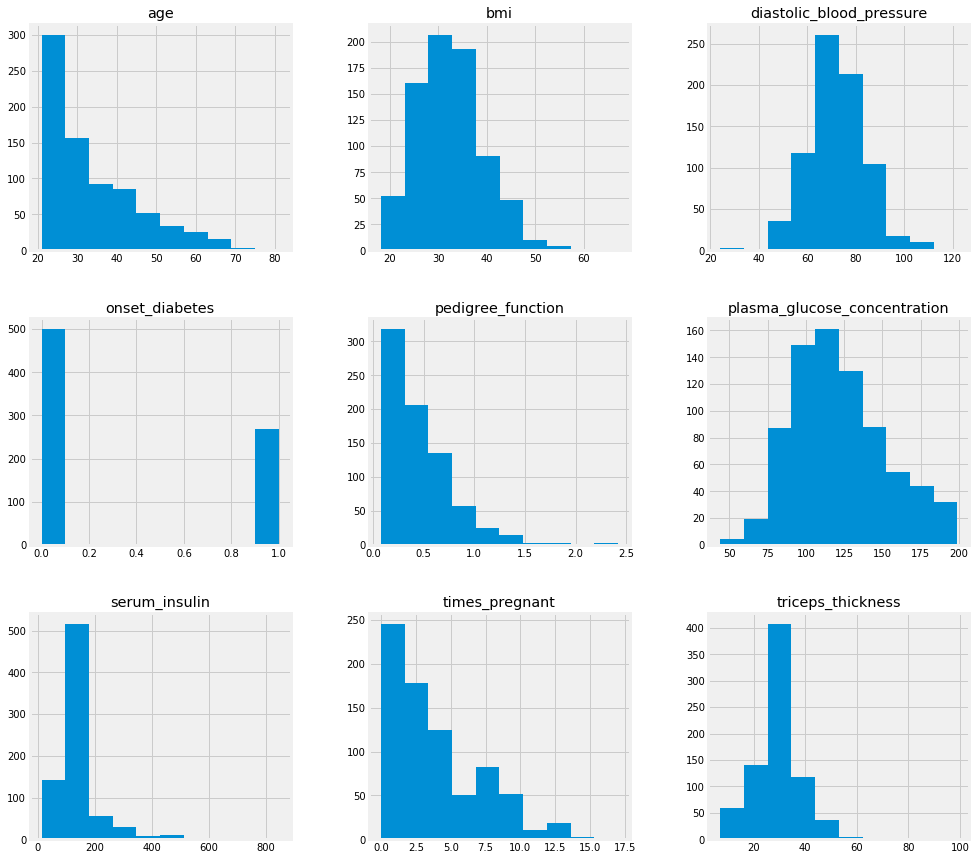

In [72]:
pima_imputed_mean.hist(figsize=(15, 15))

Nice, but notice anything off? Every single column has a vastly different mean, min, max, and standard deviation. This is also obvious through the describe method, using the following code:


In [73]:

pima_imputed_mean.describe()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.686763,72.405184,29.153420,155.548223,32.457464,0.471876,33.240885,0.348958
std,3.369578,30.435949,12.096346,8.790942,85.021108,6.875151,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.202592,29.153420,155.548223,32.400000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,155.548223,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


But why does this matter? Well, some machine learning models rely on learning methods that are affected greatly by the scale of the data, meaning that if we have a column such as diastolic_blood_pressure that lives between 24 and 122, and an age column between 21 and 81, then our learning algorithms will not learn optimally. To really see the differences in scales, let's invoke two optional parameters in the histogram method, sharex and sharey, so that we can see each graph on the same scale as every other graph, using the following code:

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x000001BA7CCA9F28>,
      dtype=object)

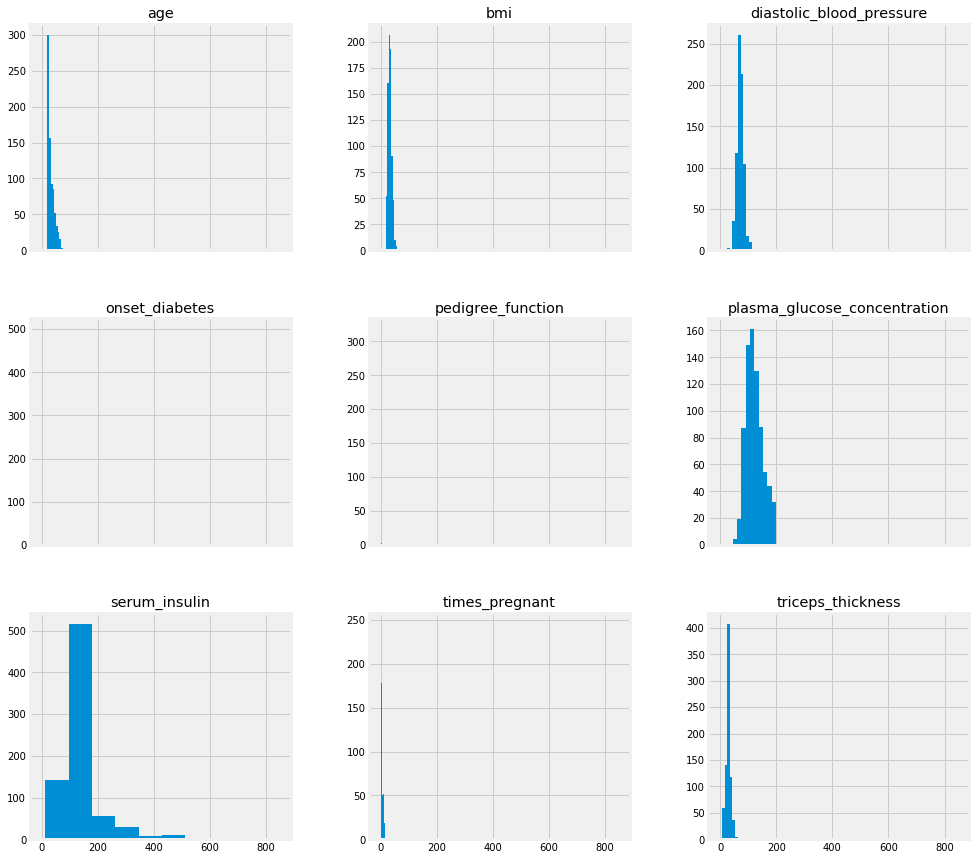

In [74]:
pima_imputed_mean.hist(figsize=(15, 15), sharex=True)
# with the same x axis (the y axis is not as important here)

It is quite clear that our data all lives on vastly different scales. Data engineers have options on how to deal with this problem in our machine learning pipelines that are under a family of operations called normalization. Normalization operations are meant to align and transform both columns and rows to a consistent set of rules. For example, a common form of normalization is to transform all quantitative columns to be between a consistent and static range of values (for example all values must be between 0 and 1). We may also impose mathematical rules such as, all columns must have the same mean and standard deviation so that they appear nicely on the same histogram (unlike the pima histograms we computed recently). Normalization techniques are meant to level the playing field of data by ensuring that all rows and columns are treated equally under the eyes of machine learning.

We will focus on three methods of data normalization:

1. Z-score standardization
2. Min-max scaling
3. Row normalization
The first two deal specifically with altering features in place, while the third option actually manipulates the rows of the data, but is still just as pertinent as the first two.

# Z-score standardization
The most common of the normalization techniques, z-score standardization, utilizes a very simple statistical idea of a z-score. The output of a z-score normalization are features that are re-scaled to have a mean of zero and a standard deviation of one. By doing this, by re-scaling our features to have a uniform mean and variance (square of standard deviation), then we allow models such as KNN to learn optimally and not skew towards larger scaled features. The formula is simple: for every column, we replace the cells with the following value:

z = (x - μ) / σ

Where:

1. z is our new value (z-score)
2. x is the previous value of the cell
3. μ is the mean of the column
4. σ is the standard deviation of the columns

Let's see an example by scaling the plasma_glucose_concentration column in our dataset:

In [75]:
print (pima['plasma_glucose_concentration'].head())

0    148.0
1     85.0
2    183.0
3     89.0
4    137.0
Name: plasma_glucose_concentration, dtype: float64


And now let's manually compute z-scores for every value in our column, using the following code:

In [76]:
# get the mean of the column
mu = pima['plasma_glucose_concentration'].mean()

# get the standard deviation of the column
sigma = pima['plasma_glucose_concentration'].std()

# calculate z scores for every value in the column.
print (((pima['plasma_glucose_concentration'] - mu) / sigma).head())

0    0.864545
1   -1.205376
2    2.014501
3   -1.073952
4    0.503130
Name: plasma_glucose_concentration, dtype: float64


We see that every single value in the column will be replaced, and also notice how now some of them are negative. This is because the resulting values represent a distance from the mean. So, if a value originally was below the mean of the column, the resulting z-score will be negative. Of course, in scikit-learn, we have built-in objects to help us out, as shown in the following code:

In [77]:
# built in z-score normalizer
from sklearn.preprocessing import StandardScaler

Text(0.5, 1.0, 'Distribution of plasma_glucose_concentration')

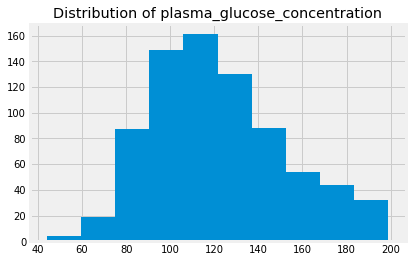

In [78]:
# mean and std before z score standardizing
pima['plasma_glucose_concentration'].mean(), pima['plasma_glucose_concentration'].std()

(121.68676277850591, 30.435948867207657)


ax = pima['plasma_glucose_concentration'].hist()
ax.set_title('Distribution of plasma_glucose_concentration')

Here, we can see the distribution of the column before doing anything. Now, let's apply a z-score scaling, as shown in the following code:

In [79]:
scaler = StandardScaler()

glucose_z_score_standardized = scaler.fit_transform(pima[['plasma_glucose_concentration']])
# note we use the double bracket notation [[ ]] because the transformer requires a dataframe

# mean of 0 (floating point error) and standard deviation of 1
glucose_z_score_standardized.mean(), glucose_z_score_standardized.std()

(-3.561965537339044e-16, 1.0)

We can see that after we apply our scaler to the column, or mean drops to zero and our standard deviation is one. Furthermore, if we take a look at the distribution of values across our recently scaled data:

Text(0.5, 1.0, 'Distribution of plasma_glucose_concentration after Z Score Scaling')

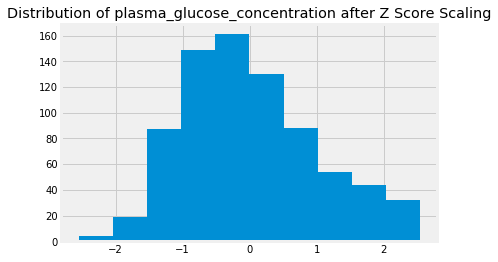

In [80]:
ax = pd.Series(glucose_z_score_standardized.reshape(-1,)).hist()
ax.set_title('Distribution of plasma_glucose_concentration after Z Score Scaling')

We will notice that our x axis is now much more constrained, while our y axis is unchanged. Also note that the shape of the data is unchanged entirely. Let's take a look at the histograms of our DataFrame after we apply a z-score transformation on every single column. When we do this, the StandardScaler will compute a mean and standard deviation for every column separately:

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x000001BA7CAAEC50>,
      dtype=object)

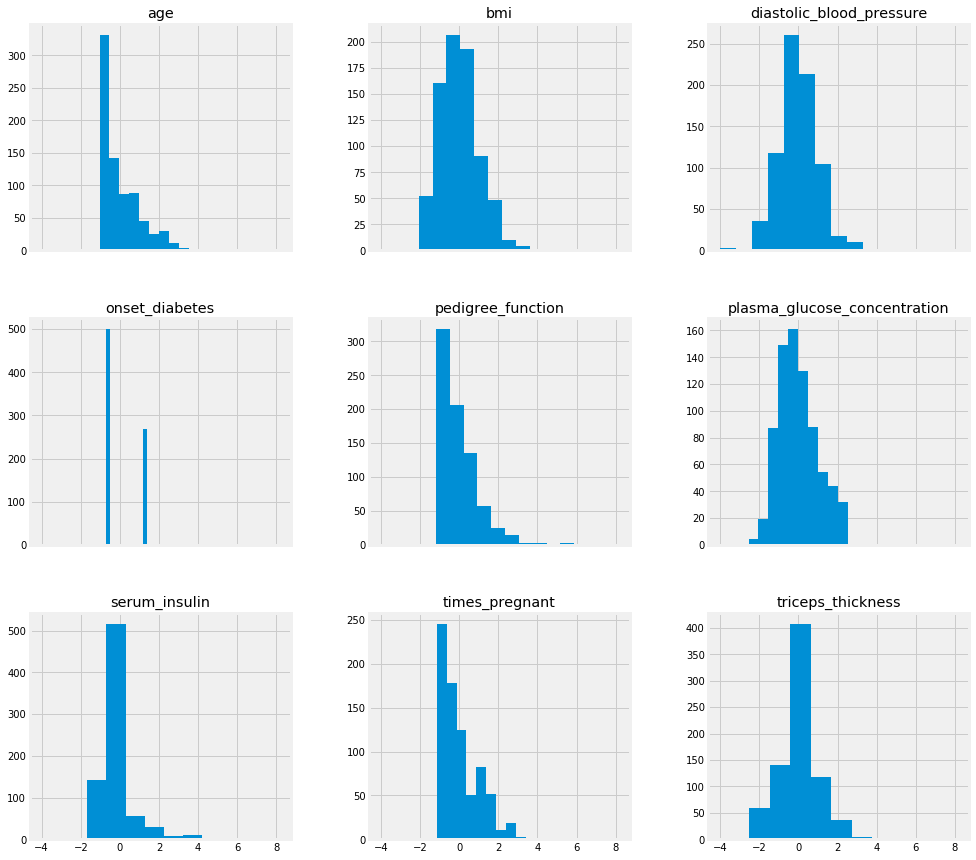

In [81]:
scale = StandardScaler() # instantiate a z-scaler object

pima_imputed_mean_scaled = pd.DataFrame(scale.fit_transform(pima_imputed_mean), columns=pima_column_names)
pima_imputed_mean_scaled.hist(figsize=(15, 15), sharex=True)
# now all share the same "space"

Notice that our x axes are all now much more constrained across the entire dataset. Let's now plug a StandardScaler into our machine learning pipeline from before:

In [82]:
knn_params = {'imputer__strategy':['mean', 'median'], 'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

mean_impute_standardize = Pipeline([('imputer', Imputer()), ('standardize', StandardScaler()), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

grid = GridSearchCV(mean_impute_standardize, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.7421875 {'classify__n_neighbors': 7, 'imputer__strategy': 'median'}


Note a few things here. We included a new set of parameters to grid search, namely the strategy of imputing missing values. Now, I am looking for the best combination of strategy and number of neighbors in our KNN attached to a z-score scaling and our result is .742, which so far is the closest score we have gotten to our goal of beating .745, and this pipeline is learning from all 768 rows. Let's now look at another method of column normalization.

# The min-max scaling method

Min-max scaling is similar to z-score normalization in that it will replace every value in a column with a new value using a formula. In this case, that formula is:

m = (x -xmin) / (xmax -xmin)

Where:

1. m is our new value
2. x is the original cell value
3. xmin is the minimum value of the column
4. xmax is the maximum value of the column
Using this formula, we will see that the values of each column will now be between zero and one. Let's take a look at an example using a built-in scikit-learn module:

In [83]:
# import the sklearn module
from sklearn.preprocessing import MinMaxScaler

#instantiate the class
min_max = MinMaxScaler()

# apply the Min Max Scaling
pima_min_maxed = pd.DataFrame(min_max.fit_transform(pima_imputed), columns=pima_column_names)

# spit out some descriptive statistics
pima_min_maxed.describe()

,times_pregnant,plasma_glucose_concentration,diastolic_blood_pressure,triceps_thickness,serum_insulin,bmi,pedigree_function,age,onset_diabetes
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,0.226180,0.501205,0.493930,0.240798,0.170130,0.291564,0.168179,0.204015,0.348958
std,0.198210,0.196361,0.123432,0.095554,0.102189,0.140596,0.141473,0.196004,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.058824,0.359677,0.408163,0.195652,0.129207,0.190184,0.070773,0.050000,0.000000
50%,0.176471,0.470968,0.491863,0.240798,0.170130,0.290389,0.125747,0.133333,0.000000
75%,0.352941,0.620968,0.571429,0.271739,0.170130,0.376278,0.234095,0.333333,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Notice how the min are all zeros and the max values are all ones. Note further that the standard deviations are now all very very small, a side effect of this type of scaling. This can hurt some models as it takes away weight from outliers. Let's plug our new normalization technique into our pipeline:

In [84]:
knn_params = {'imputer__strategy': ['mean', 'median'], 'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

mean_impute_standardize = Pipeline([('imputer', Imputer()), ('standardize', MinMaxScaler()), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

grid = GridSearchCV(mean_impute_standardize, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.74609375 {'classify__n_neighbors': 4, 'imputer__strategy': 'mean'}


Woah, this is the best accuracy we've gotten so far working with the missing data and using all of the 768 original rows in the dataset. It seems as though the min-max scaling is helping our KNN a great deal! Wonderful; let's try a third type of normalization, and this time let's move away from normalizing columns and onto normalizing rows instead.

# The row normalization method

Our final normalization method works row-wise instead of column-wise. Instead of calculating statistics on each column, mean, min, max, and so on, the row normalization technique will ensure that each row of data has a unit norm, meaning that each row will be the same vector length. Imagine if each row of data belonged to an n-dimensional space; each one would have a vector norm, or length. Another way to put it is if we consider every row to be a vector in space:

1. x = (x1, x2, ..., xn)

Where 1, 2, ..., n in the case of Pima would be 8, 1 for each feature (not including the response), the norm would be calculated as: 

2. ||x|| = √(x12 + x22 + ... + xn2)

This is called the L-2 Norm. Other types of norms exist, but we will not get into that in this text. Instead, we are concerned with making sure that every single row has the same norm. This comes in handy, especially when working with text data or clustering algorithms.

Before doing anything, let's see the average norm of our mean-imputed matrix, using the following code:

In [85]:
np.sqrt((pima_imputed**2).sum(axis=1)).mean() 
# average vector length of imputed matrix

223.3622202582376

Now, let's bring in our row-normalizer, as shown in the following code:

In [86]:
from sklearn.preprocessing import Normalizer # our row normalizer

normalize = Normalizer()

pima_normalized = pd.DataFrame(normalize.fit_transform(pima_imputed), columns=pima_column_names)

np.sqrt((pima_normalized**2).sum(axis=1)).mean()
# average vector length of row normalized imputed matrix

1.0

After normalizing, we see that every single row has a norm of one now. Let's see how this method fares in our pipeline:

In [87]:
knn_params = {'imputer__strategy': ['mean', 'median'], 'classify__n_neighbors':[1, 2, 3, 4, 5, 6, 7]}

mean_impute_normalize = Pipeline([('imputer', Imputer()), ('normalize', Normalizer()), ('classify', knn)])
X = pima.drop('onset_diabetes', axis=1)
y = pima['onset_diabetes']

grid = GridSearchCV(mean_impute_normalize, knn_params)
grid.fit(X, y)

print (grid.best_score_, grid.best_params_)

0.6822916666666666 {'classify__n_neighbors': 6, 'imputer__strategy': 'mean'}


Not great, but worth a try. Now that we have seen three different methods of data normalization, let's put it all together and see how we did on this dataset.

There are many learning algorithms that are affected by the scale of data. Here is a list of some popular learning algorithms that are affected by the scale of data:

1. KNN-due to its reliance on the Euclidean Distance
2. K-Means Clustering - same reasoning as KNN
3. Logistic regression, SVM, neural networks—if you are using gradient descent to learn weights
4. Principal component analysis—eigen vectors will be skewed towards larger columns